# Product Review Intelligence — ML Pipeline

| Output | Scope | Method |
|---|---|---|
| Pros | per `product_id` | K-Means on positive reviews |
| Cons | per `product_id` | K-Means on negative reviews |
| Common Complaints | per `product_id` | K-Means on negative reviews (with frequency) |
| Trend Analysis | per `product_id` & `product_parent` | Ridge Regression (slope) |
| Sentiment Summary | per `product_id` & `product_parent` | GroupBy aggregation (labels already exist) |

> `sentiment_label` is pre-derived from star ratings — no classification model needed.


In [18]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [19]:
DATA_DIR         = '../../data/processed'
OUTPUT_DIR       = '../../data/processed/ml_outputs'
CATEGORIES       = ['apparel', 'beauty', 'books', 'furniture', 'mobile', 'outdoors']

LOAD_COLS = [
    'product_id', 'product_parent', 'review', 'sentiment_label',
    'review_year', 'review_month', 'helpfulness_ratio',
    'helpful_votes', 'total_votes', 'verified_purchase', 'vine', 'source_category'
]

SAMPLE_PER_CAT   = 15_000   # rows sampled per category at load time
MIN_REVIEWS      = 3        # minimum reviews per product_id to include
TFIDF_MAX_FEAT   = 1500     # TF-IDF vocabulary size
SVD_N_COMPONENTS = 30       # LSA dimensionality
K_RANGE          = range(2, 8)
VAL_TUNE_SAMPLE  = 2_000    # reviews sampled for k tuning on val set
N_CLUSTER_TERMS  = 8        # top terms per cluster centroid
TREND_THRESHOLD  = 0.005    # min slope magnitude to classify as improving/declining
RANDOM_STATE     = 42

os.makedirs(OUTPUT_DIR, exist_ok=True)
print('Config ready.')

Config ready.


## 1. Data Loading

In [20]:
frames = []
for cat in CATEGORIES:
    df = pd.read_parquet(f'{DATA_DIR}/{cat}_processed.parquet', columns=LOAD_COLS)
    df = df.sample(n=min(SAMPLE_PER_CAT, len(df)), random_state=RANDOM_STATE)
    frames.append(df)

data = pd.concat(frames, ignore_index=True)
data['sentiment_label'] = data['sentiment_label'].str.strip().str.lower()

print(f"Loaded : {len(data):>8,} rows  ({SAMPLE_PER_CAT:,} per category × {len(CATEGORIES)} categories)")
print(f"Products: {data['product_id'].nunique():>7,} unique product_ids")
print(f"Parents : {data['product_parent'].nunique():>7,} unique product_parents")
print()
print(data['sentiment_label'].value_counts())

Loaded :   90,000 rows  (15,000 per category × 6 categories)
Products:  68,199 unique product_ids
Parents :  63,196 unique product_parents

sentiment_label
positive    69539
negative    12420
neutral      8041
Name: count, dtype: int64


## 2. Filtering & Feature Engineering

In [21]:
# Keep only products with enough reviews for meaningful analysis
review_counts = data.groupby('product_id').size()
valid_products = review_counts[review_counts >= MIN_REVIEWS].index
data = data[data['product_id'].isin(valid_products)].reset_index(drop=True)

print(f"After MIN_REVIEWS={MIN_REVIEWS} filter: {len(data):,} rows | {data['product_id'].nunique():,} products")

# Binary encode Y/N columns (one-hot not needed — both are binary)
data['verified_purchase_enc'] = (data['verified_purchase'] == 'Y').astype(np.int8)
data['vine_enc']               = (data['vine'] == 'Y').astype(np.int8)

# Cyclical month encoding for trend model (avoids Jan=1, Dec=12 discontinuity)
data['month_sin'] = np.sin(2 * np.pi * data['review_month'] / 12).astype(np.float32)
data['month_cos'] = np.cos(2 * np.pi * data['review_month'] / 12).astype(np.float32)

data['helpfulness_ratio'] = data['helpfulness_ratio'].fillna(0).astype(np.float32)

print()
data[['verified_purchase_enc', 'vine_enc', 'month_sin', 'month_cos', 'helpfulness_ratio']].describe()

After MIN_REVIEWS=3 filter: 20,259 rows | 3,494 products



,verified_purchase_enc,vine_enc,month_sin,month_cos,helpfulness_ratio
count,20259.000000,20259.000000,2.025900e+04,2.025900e+04,20259.000000
mean,0.893924,0.000888,5.943730e-02,-2.155113e-02,0.213010
std,0.307943,0.029795,6.997711e-01,7.115985e-01,0.379369
min,0.000000,0.000000,-1.000000e+00,-1.000000e+00,0.000000
25%,1.000000,0.000000,-5.000000e-01,-8.660254e-01,0.000000
50%,1.000000,0.000000,1.224647e-16,6.123234e-17,0.000000
75%,1.000000,0.000000,8.660254e-01,8.660254e-01,0.333333
max,1.000000,1.000000,1.000000e+00,1.000000e+00,1.000000


## 3. Train / Validation / Test Split

Stratified on `sentiment_label` to preserve class ratios across all three splits.  
**70 % train — 15 % val — 15 % test**

In [22]:
idx = data.index.to_numpy()

train_idx, temp_idx = train_test_split(
    idx, test_size=0.30,
    stratify=data['sentiment_label'],
    random_state=RANDOM_STATE
)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50,
    stratify=data.loc[temp_idx, 'sentiment_label'],
    random_state=RANDOM_STATE
)

train_df = data.loc[train_idx].reset_index(drop=True)
val_df   = data.loc[val_idx].reset_index(drop=True)
test_df  = data.loc[test_idx].reset_index(drop=True)

print(f"Train : {len(train_df):>10,}  ({len(train_df)/len(data)*100:.1f}%)")
print(f"Val   : {len(val_df):>10,}  ({len(val_df)/len(data)*100:.1f}%)")
print(f"Test  : {len(test_df):>10,}  ({len(test_df)/len(data)*100:.1f}%)")
print()
print("Train sentiment distribution:")
print(train_df['sentiment_label'].value_counts())

Train :     14,181  (70.0%)
Val   :      3,039  (15.0%)
Test  :      3,039  (15.0%)

Train sentiment distribution:
sentiment_label
positive    11265
negative     1739
neutral      1177
Name: count, dtype: int64


## 4. K-Means Clustering — Pros, Cons & Complaints

**Pipeline:** `TF-IDF (train set)` → `TruncatedSVD (LSA)` → tune `k` via silhouette on val → refit K-Means → assign clusters to all reviews → aggregate top clusters per `product_id`

- **Pros** = top clusters from positive reviews  
- **Cons / Complaints** = top clusters from negative reviews (complaints include frequency count)

In [23]:
def build_tfidf_svd(texts, max_features, n_components, random_state):
    tfidf = TfidfVectorizer(
        max_features=max_features,
        stop_words='english',
        min_df=5,
        ngram_range=(1, 2),
        sublinear_tf=True
    )
    X = tfidf.fit_transform(texts)
    svd = TruncatedSVD(n_components=n_components, random_state=random_state)
    X_svd = svd.fit_transform(X)
    return tfidf, svd, X_svd


def tune_k(X, k_range, random_state):
    scores = {}
    for k in k_range:
        km  = KMeans(n_clusters=k, n_init=5, random_state=random_state)
        lbl = km.fit_predict(X)
        scores[k] = silhouette_score(X, lbl, sample_size=5_000, random_state=random_state)
        print(f"  k={k}  silhouette={scores[k]:.4f}")
    return scores


def fit_kmeans(X, k, random_state):
    km = KMeans(n_clusters=k, n_init=10, random_state=random_state)
    km.fit(X)
    return km


def batch_predict(tfidf, svd, km, texts, batch_size=50_000):
    """Memory-safe prediction in chunks for large text series."""
    texts = texts.reset_index(drop=True)
    parts = []
    for start in range(0, len(texts), batch_size):
        chunk = texts.iloc[start:start + batch_size]
        X     = svd.transform(tfidf.transform(chunk))
        parts.append(km.predict(X))
    return np.concatenate(parts)


def cluster_top_terms(tfidf, svd, km, n_terms):
    """Recover top TF-IDF terms per cluster centroid via SVD components."""
    feat         = np.array(tfidf.get_feature_names_out())
    centroid_tfidf = km.cluster_centers_ @ svd.components_
    return {
        i: feat[c.argsort()[::-1][:n_terms]].tolist()
        for i, c in enumerate(centroid_tfidf)
    }


def aggregate_top_clusters(df, cluster_col, cluster_terms, id_col='product_id', top_n=3):
    """Return top-N cluster themes per product_id as a list."""
    agg = (
        df.groupby([id_col, cluster_col])
          .size()
          .reset_index(name='cnt')
          .sort_values([id_col, 'cnt'], ascending=[True, False])
    )
    top = agg.groupby(id_col).head(top_n).copy()
    top['theme'] = top[cluster_col].map(lambda c: ', '.join(cluster_terms[c]))
    return top.groupby(id_col)['theme'].apply(list).reset_index()


print('Helper functions defined.')

Helper functions defined.


### 4a. Pros — K-Means on Positive Reviews

In [24]:
# --- Fit TF-IDF + SVD on ALL positive train reviews ---
pos_train = train_df[train_df['sentiment_label'] == 'positive'].reset_index(drop=True)

print(f"Fitting TF-IDF + SVD on ALL {len(pos_train):,} positive train reviews...")
tfidf_pos, svd_pos, _ = build_tfidf_svd(
    pos_train['review'], TFIDF_MAX_FEAT, SVD_N_COMPONENTS, RANDOM_STATE
)
# Sparse TF-IDF matrix over full train set (reused for K-Means and per-product averaging)
X_pos_tfidf = tfidf_pos.transform(pos_train['review'].values)
X_pos_svd   = svd_pos.transform(X_pos_tfidf)

# --- Tune k on positive val sample ---
pos_val        = val_df[val_df['sentiment_label'] == 'positive']
pos_val_sample = pos_val.sample(min(VAL_TUNE_SAMPLE, len(pos_val)), random_state=RANDOM_STATE)
X_pos_val      = svd_pos.transform(tfidf_pos.transform(pos_val_sample['review']))

print(f"\nTuning k on {len(pos_val_sample):,} positive val reviews:")
pos_k_scores = tune_k(X_pos_val, K_RANGE, RANDOM_STATE)
best_k_pos   = max(pos_k_scores, key=pos_k_scores.get)
print(f"\nBest k for pros: {best_k_pos}  (silhouette={pos_k_scores[best_k_pos]:.4f})")

# --- K-Means on full positive train SVD features ---
km_pos    = fit_kmeans(X_pos_svd, best_k_pos, RANDOM_STATE)
pro_terms = cluster_top_terms(tfidf_pos, svd_pos, km_pos, N_CLUSTER_TERMS)

print("\nGlobal pro cluster themes (K-Means):")
for cid, terms in pro_terms.items():
    print(f"  Cluster {cid}: {', '.join(terms)}")

# --- Per-product pros: average TF-IDF over each product's train reviews ---
# Uses the same full train TF-IDF matrix — no val/test data involved.
vocab_pos = np.array(tfidf_pos.get_feature_names_out())

product_pros_list = []
for pid, idx in pos_train.groupby('product_id').groups.items():
    X_prod = X_pos_tfidf[idx.values]
    avg    = np.asarray(X_prod.mean(axis=0)).flatten()
    top    = avg.argsort()[::-1][:N_CLUSTER_TERMS]
    terms  = [vocab_pos[j] for j in top if avg[j] > 0]
    product_pros_list.append({'product_id': pid, 'pros': terms})

product_pros = pd.DataFrame(product_pros_list)

print(f"\nPros generated for {len(product_pros):,} products")
print(product_pros.head(3))

Fitting TF-IDF + SVD on ALL 11,265 positive train reviews...

Tuning k on 2,000 positive val reviews:
  k=2  silhouette=0.2471
  k=3  silhouette=0.1446
  k=4  silhouette=0.1515
  k=5  silhouette=0.1431
  k=6  silhouette=0.1482
  k=7  silhouette=0.1021

Best k for pros: 2  (silhouette=0.2471)

Global pro cluster themes (K-Means):
  Cluster 0: game, great, love, fun, good, like, easy, just
  Cluster 1: stars, stars great, stars love, stars good, great, love, good, stars nice

Pros generated for 3,253 products
   product_id                                               pros
0  0060173289  [long, minute, novel, long time, believe, beau...
1  0060175400  [novel, family, character, bible, multiple, re...
2  0060193395  [program, exercise, book, results, body, weigh...


### 4b. Cons & Complaints — K-Means on Negative Reviews

In [25]:
# --- Fit TF-IDF + SVD on ALL negative train reviews ---
neg_train = train_df[train_df['sentiment_label'] == 'negative'].reset_index(drop=True)

print(f"Fitting TF-IDF + SVD on ALL {len(neg_train):,} negative train reviews...")
tfidf_neg, svd_neg, _ = build_tfidf_svd(
    neg_train['review'], TFIDF_MAX_FEAT, SVD_N_COMPONENTS, RANDOM_STATE
)
# Sparse TF-IDF matrix over full train set (reused for K-Means, per-product averaging, complaints)
X_neg_tfidf = tfidf_neg.transform(neg_train['review'].values)
X_neg_svd   = svd_neg.transform(X_neg_tfidf)

# --- Tune k on negative val sample ---
neg_val        = val_df[val_df['sentiment_label'] == 'negative']
neg_val_sample = neg_val.sample(min(VAL_TUNE_SAMPLE, len(neg_val)), random_state=RANDOM_STATE)
X_neg_val      = svd_neg.transform(tfidf_neg.transform(neg_val_sample['review']))

print(f"\nTuning k on {len(neg_val_sample):,} negative val reviews:")
neg_k_scores = tune_k(X_neg_val, K_RANGE, RANDOM_STATE)
best_k_neg   = max(neg_k_scores, key=neg_k_scores.get)
print(f"\nBest k for cons: {best_k_neg}  (silhouette={neg_k_scores[best_k_neg]:.4f})")

# --- K-Means on full negative train SVD features ---
km_neg    = fit_kmeans(X_neg_svd, best_k_neg, RANDOM_STATE)
con_terms = cluster_top_terms(tfidf_neg, svd_neg, km_neg, N_CLUSTER_TERMS)

print("\nGlobal con / complaint cluster themes (K-Means):")
for cid, terms in con_terms.items():
    print(f"  Cluster {cid}: {', '.join(terms)}")

# --- Per-product cons: average TF-IDF over each product's train reviews ---
vocab_neg = np.array(tfidf_neg.get_feature_names_out())

product_cons_list = []
for pid, idx in neg_train.groupby('product_id').groups.items():
    X_prod = X_neg_tfidf[idx.values]
    avg    = np.asarray(X_prod.mean(axis=0)).flatten()
    top    = avg.argsort()[::-1][:N_CLUSTER_TERMS]
    terms  = [vocab_neg[j] for j in top if avg[j] > 0]
    product_cons_list.append({'product_id': pid, 'cons': terms})

product_cons = pd.DataFrame(product_cons_list)

# --- Complaints: K-Means cluster assignment on train negative reviews ---
neg_train['con_cluster'] = km_neg.predict(X_neg_svd)

complaints_detail = (
    neg_train.groupby(['product_id', 'con_cluster'])
             .size()
             .reset_index(name='complaint_count')
)
complaints_detail['complaint_theme'] = complaints_detail['con_cluster'].map(
    lambda c: ', '.join(con_terms[c])
)
complaints_detail = (
    complaints_detail
    .sort_values(['product_id', 'complaint_count'], ascending=[True, False])
    .groupby('product_id').head(3)
    .drop(columns='con_cluster')
    .reset_index(drop=True)
)

complaints_dict = (
    complaints_detail
    .groupby('product_id')
    .apply(lambda g: g[['complaint_theme', 'complaint_count']].to_dict('records'))
    .to_dict()
)

print(f"\nCons generated for     {len(product_cons):,} products")
print(f"Complaints detailed for {len(complaints_dict):,} products")
print(product_cons.head(3))

Fitting TF-IDF + SVD on ALL 1,739 negative train reviews...

Tuning k on 372 negative val reviews:
  k=2  silhouette=0.3076
  k=3  silhouette=0.0967
  k=4  silhouette=0.1567
  k=5  silhouette=0.1099
  k=6  silhouette=0.1502
  k=7  silhouette=0.0950

Best k for cons: 2  (silhouette=0.3076)

Global con / complaint cluster themes (K-Means):
  Cluster 0: game, stars, app, like, just, don, time, good
  Cluster 1: star, work, boring, play, didn, did, money, got

Cons generated for     1,173 products
Complaints detailed for 1,173 products
   product_id                                               cons
0  0060175400  [american, apparent, men, book, facts, persona...
1  0060193395  [program, provide, later, book, know, working,...
2  0060195347  [quit, expecting, loved, books, waste time, lo...


## 5. Trend Analysis — Ridge Regression

**Approach:** Aggregate monthly sentiment rate (% positive) per product → fit Ridge regression with time features → slope determines trend direction.  
**Time split:** First 70% of unique time periods = train, next 15% = val (alpha tuning), last 15% = test.  
**Trend classification:** slope > threshold → *improving*, slope < −threshold → *declining*, else → *stable*.

In [26]:
# Monthly sentiment aggregation per product
monthly = (
    data.groupby(['product_id', 'product_parent', 'source_category', 'review_year', 'review_month'])
        .agg(
            total_reviews   = ('sentiment_label', 'count'),
            positive_count  = ('sentiment_label', lambda x: (x == 'positive').sum()),
            avg_helpfulness = ('helpfulness_ratio', 'mean'),
            vp_rate         = ('verified_purchase_enc', 'mean'),
            vine_rate       = ('vine_enc', 'mean')
        )
        .reset_index()
)

monthly['sentiment_rate'] = monthly['positive_count'] / monthly['total_reviews']
monthly['month_sin']      = np.sin(2 * np.pi * monthly['review_month'] / 12)
monthly['month_cos']      = np.cos(2 * np.pi * monthly['review_month'] / 12)

print(f"Monthly aggregation: {len(monthly):,} rows")
print(f"Year range: {monthly['review_year'].min()} – {monthly['review_year'].max()}")
print(monthly[['sentiment_rate','total_reviews']].describe().round(3))

Monthly aggregation: 15,840 rows
Year range: 1997 – 2015
       sentiment_rate  total_reviews
count       15840.000      15840.000
mean            0.787          1.279
std             0.394          0.995
min             0.000          1.000
25%             1.000          1.000
50%             1.000          1.000
75%             1.000          1.000
max             1.000         33.000


In [27]:
# Time-based split: sort unique (year, month) periods, split 70/15/15
time_periods = (
    monthly[['review_year','review_month']]
    .drop_duplicates()
    .sort_values(['review_year','review_month'])
    .reset_index(drop=True)
)

n  = len(time_periods)
t1 = int(n * 0.70)
t2 = int(n * 0.85)

train_periods = time_periods.iloc[:t1]
val_periods   = time_periods.iloc[t1:t2]
test_periods  = time_periods.iloc[t2:]

m_train = monthly.merge(train_periods, on=['review_year','review_month'])
m_val   = monthly.merge(val_periods,   on=['review_year','review_month'])
m_test  = monthly.merge(test_periods,  on=['review_year','review_month'])

print(f"Trend split — Train: {len(m_train):,} | Val: {len(m_val):,} | Test: {len(m_test):,}")
print(f"Train years: {m_train.review_year.min()}–{m_train.review_year.max()}")
print(f"Val years  : {m_val.review_year.min()}–{m_val.review_year.max()}")
print(f"Test years : {m_test.review_year.min()}–{m_test.review_year.max()}")

Trend split — Train: 998 | Val: 2,257 | Test: 12,585
Train years: 1997–2010
Val years  : 2010–2013
Test years : 2013–2015


In [28]:
TREND_FEATURES = ['review_year', 'month_sin', 'month_cos', 'avg_helpfulness', 'vp_rate', 'vine_rate']
TREND_TARGET   = 'sentiment_rate'

X_tr  = m_train[TREND_FEATURES].values
y_tr  = m_train[TREND_TARGET].values
X_val = m_val[TREND_FEATURES].values
y_val = m_val[TREND_TARGET].values
X_te  = m_test[TREND_FEATURES].values
y_te  = m_test[TREND_TARGET].values

scaler = StandardScaler()
X_tr  = scaler.fit_transform(X_tr)
X_val = scaler.transform(X_val)
X_te  = scaler.transform(X_te)

# Hyperparameter tuning: alpha on validation set
alphas  = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]
val_r2  = {}

print("Ridge alpha tuning on validation set:")
for alpha in alphas:
    ridge    = Ridge(alpha=alpha)
    ridge.fit(X_tr, y_tr)
    val_r2[alpha] = ridge.score(X_val, y_val)
    print(f"  alpha={alpha:<8}  val R²={val_r2[alpha]:.4f}")

best_alpha = max(val_r2, key=val_r2.get)
print(f"\nBest alpha: {best_alpha}  (val R²={val_r2[best_alpha]:.4f})")

# Refit with best alpha and evaluate on test
ridge_best = Ridge(alpha=best_alpha)
ridge_best.fit(X_tr, y_tr)
test_r2 = ridge_best.score(X_te, y_te)
print(f"Test R²  : {test_r2:.4f}")

Ridge alpha tuning on validation set:
  alpha=0.001     val R²=0.0030
  alpha=0.01      val R²=0.0030
  alpha=0.1       val R²=0.0030
  alpha=1.0       val R²=0.0030
  alpha=10.0      val R²=0.0031
  alpha=100.0     val R²=0.0032
  alpha=1000.0    val R²=0.0033

Best alpha: 1000.0  (val R²=0.0033)
Test R²  : -0.0087


In [29]:
def ols_slope(x, y):
    xm, ym = x.mean(), y.mean()
    denom  = ((x - xm) ** 2).sum()
    return 0.0 if denom < 1e-12 else ((x - xm) * (y - ym)).sum() / denom


def classify_trend(grp):
    if len(grp) < 3:
        return pd.Series({'slope': np.nan, 'trend': 'insufficient_data'})
    x     = (grp['review_year'] + grp['review_month'] / 12).values.astype(float)
    y     = grp['sentiment_rate'].values.astype(float)
    slope = ols_slope(x, y)
    if np.isnan(slope) or abs(slope) < TREND_THRESHOLD:
        trend = 'stable'
    elif slope > 0:
        trend = 'improving'
    else:
        trend = 'declining'
    return pd.Series({'slope': round(float(slope), 6), 'trend': trend})


print("Computing per-product_id trend...")
product_trend = (
    monthly.groupby('product_id', group_keys=False)
           .apply(classify_trend)
           .reset_index()
)

print("Computing per-product_parent trend...")
parent_trend = (
    monthly.groupby('product_parent', group_keys=False)
           .apply(classify_trend)
           .reset_index()
)
parent_trend.columns = ['product_parent', 'parent_slope', 'parent_trend']

print("\nProduct trend distribution:")
print(product_trend['trend'].value_counts())
print("\nParent trend distribution:")
print(parent_trend['parent_trend'].value_counts())

Computing per-product_id trend...
Computing per-product_parent trend...

Product trend distribution:
trend
stable               3014
declining            2450
improving            2128
insufficient_data     743
Name: count, dtype: int64

Parent trend distribution:
parent_trend
stable               2670
declining            2321
improving            2016
insufficient_data     705
Name: count, dtype: int64


## 6. Sentiment Summary Aggregation

No model needed — `sentiment_label` is pre-derived. Pure aggregation per `product_id` and `product_parent`.

In [30]:
def sentiment_pivot(df, group_col):
    agg = (
        df.groupby([group_col, 'sentiment_label'])
          .size()
          .reset_index(name='count')
    )
    wide = agg.pivot_table(
        index=group_col, columns='sentiment_label',
        values='count', fill_value=0
    ).reset_index()
    wide.columns.name = None
    for col in ['positive','negative','neutral']:
        if col not in wide.columns:
            wide[col] = 0
    wide['total_reviews'] = wide['positive'] + wide['negative'] + wide['neutral']
    wide['positive_pct']  = (wide['positive'] / wide['total_reviews'] * 100).round(1)
    wide['negative_pct']  = (wide['negative'] / wide['total_reviews'] * 100).round(1)
    wide['neutral_pct']   = (wide['neutral']  / wide['total_reviews'] * 100).round(1)
    return wide


sentiment_by_product = sentiment_pivot(data, 'product_id')
sentiment_by_parent  = sentiment_pivot(data, 'product_parent')

# Attach source_category to product-level summary
category_map = data[['product_id','product_parent','source_category']].drop_duplicates('product_id')
sentiment_by_product = sentiment_by_product.merge(category_map, on='product_id', how='left')

print(f"Sentiment summary — products : {len(sentiment_by_product):,}")
print(f"Sentiment summary — parents  : {len(sentiment_by_parent):,}")
print()
print(sentiment_by_product.head(3).to_string())

Sentiment summary — products : 8,335
Sentiment summary — parents  : 7,712

   product_id  negative  neutral  positive  total_reviews  positive_pct  negative_pct  neutral_pct  product_parent source_category
0  0028610105       0.0      0.0       3.0            3.0         100.0           0.0          0.0       755707312           Books
1  006001203X       1.0      1.0       2.0            4.0          50.0          25.0         25.0       183030674           Books
2  0060096543       0.0      0.0       6.0            6.0         100.0           0.0          0.0       836761064           Books


## 7. Final Output Assembly

In [32]:
# Per product_id: sentiment + pros + cons + complaints + trend
final_product = (
    sentiment_by_product
    .merge(product_pros,   on='product_id', how='left')
    .merge(product_cons,   on='product_id', how='left')
    .merge(product_trend[['product_id','slope','trend']], on='product_id', how='left')
)
final_product['complaints'] = final_product['product_id'].map(complaints_dict)

# Per product_parent: sentiment + trend
final_parent = sentiment_by_parent.merge(parent_trend, on='product_parent', how='left')

# Save outputs
final_product.to_parquet(f'{OUTPUT_DIR}/product_intelligence.parquet',  index=False)
final_parent.to_parquet( f'{OUTPUT_DIR}/parent_intelligence.parquet',   index=False)
monthly.to_parquet(      f'{OUTPUT_DIR}/monthly_sentiment_trend.parquet', index=False)

print(f"Saved product_intelligence  : {len(final_product):,} rows")
print(f"Saved parent_intelligence   : {len(final_parent):,} rows")
print(f"Saved monthly_sentiment_trend: {len(monthly):,} rows")
print()
print("Columns in product_intelligence:")
print(final_product.columns.tolist())
print()
print("Sample output (5 products):")
display_cols = ['product_id','source_category','total_reviews',
                'positive_pct','negative_pct','trend','pros','cons','complaints']
print(final_product[display_cols].head(5).to_string())

Saved product_intelligence  : 8,335 rows
Saved parent_intelligence   : 7,712 rows
Saved monthly_sentiment_trend: 40,231 rows

Columns in product_intelligence:
['product_id', 'negative', 'neutral', 'positive', 'total_reviews', 'positive_pct', 'negative_pct', 'neutral_pct', 'product_parent', 'source_category', 'pros', 'cons', 'slope', 'trend', 'complaints']

Sample output (5 products):
   product_id source_category  total_reviews  positive_pct  negative_pct      trend                                              pros                                                cons                                                                                       complaints
0  0028610105           Books            3.0         100.0           0.0     stable  [game, great, love, fun, good, like, just, easy]                                                 NaN                                                                                              NaN
1  006001203X           Books            4.0   

## 8. Test Set Visualizations

All plots below use **test set data only**.

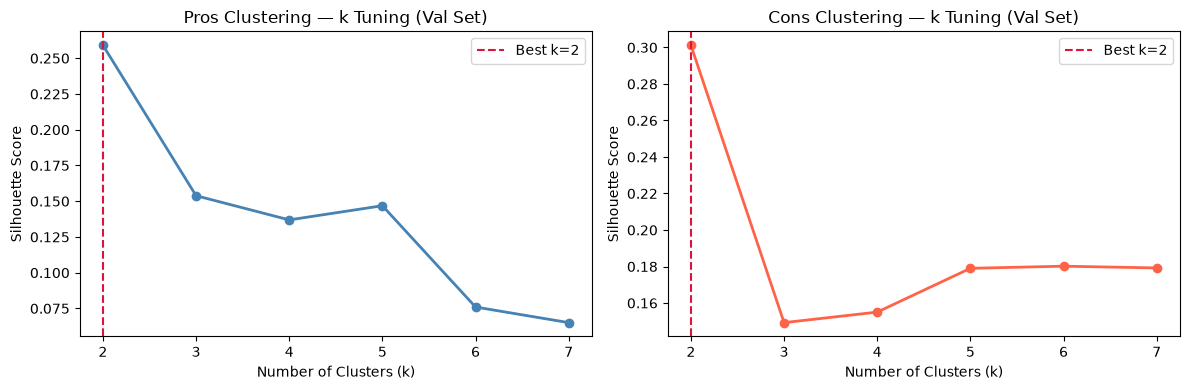

In [33]:
# Plot 1: Silhouette scores for k tuning (pros vs cons)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

k_list       = list(pos_k_scores.keys())
sil_pos      = [pos_k_scores[k] for k in k_list]
sil_neg      = [neg_k_scores[k] for k in k_list]

ax1.plot(k_list, sil_pos, 'o-', color='steelblue', linewidth=2)
ax1.axvline(best_k_pos, linestyle='--', color='crimson', label=f'Best k={best_k_pos}')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Silhouette Score')
ax1.set_title('Pros Clustering — k Tuning (Val Set)')
ax1.set_xticks(k_list)
ax1.legend()

ax2.plot(k_list, sil_neg, 'o-', color='tomato', linewidth=2)
ax2.axvline(best_k_neg, linestyle='--', color='crimson', label=f'Best k={best_k_neg}')
ax2.set_xlabel('Number of Clusters (k)')
ax2.set_ylabel('Silhouette Score')
ax2.set_title('Cons Clustering — k Tuning (Val Set)')
ax2.set_xticks(k_list)
ax2.legend()

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/silhouette_tuning.png', dpi=100)
plt.show()

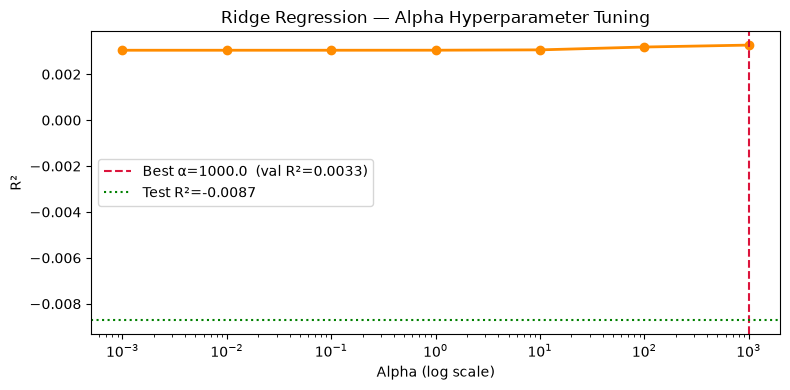

In [34]:
# Plot 2: Ridge alpha tuning (val R²)
fig, ax = plt.subplots(figsize=(8, 4))

sorted_alphas = sorted(val_r2.keys())
sorted_r2     = [val_r2[a] for a in sorted_alphas]

ax.semilogx(sorted_alphas, sorted_r2, 'o-', color='darkorange', linewidth=2)
ax.axvline(best_alpha, linestyle='--', color='crimson', label=f'Best α={best_alpha}  (val R²={val_r2[best_alpha]:.4f})')
ax.axhline(test_r2, linestyle=':', color='green', label=f'Test R²={test_r2:.4f}')
ax.set_xlabel('Alpha (log scale)')
ax.set_ylabel('R²')
ax.set_title('Ridge Regression — Alpha Hyperparameter Tuning')
ax.legend()

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/ridge_alpha_tuning.png', dpi=100)
plt.show()

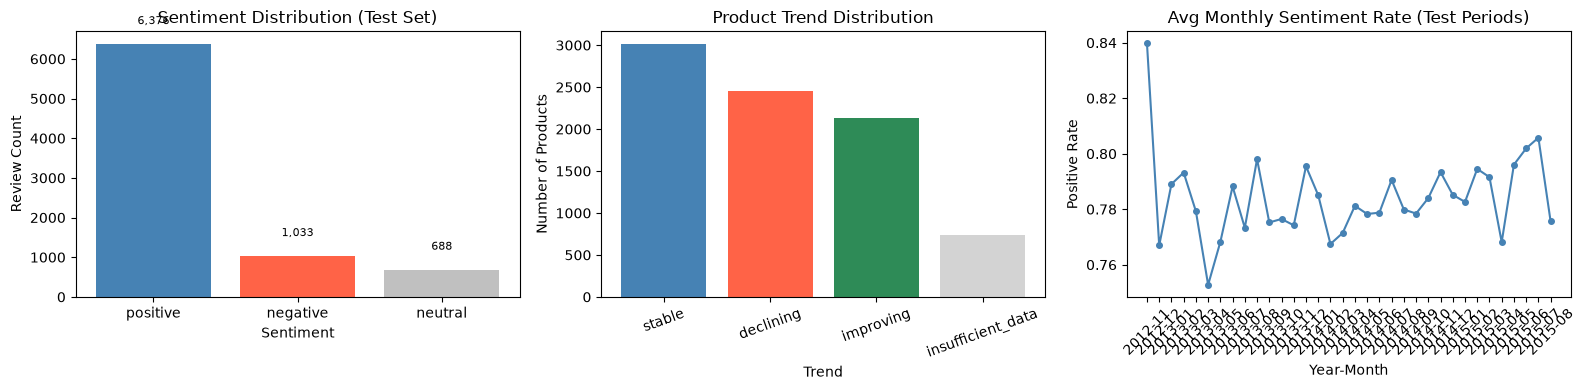

In [35]:
# Plot 3: Test-set sentiment distribution & product trend breakdown
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 3a: Sentiment on test set
sent_test = test_df['sentiment_label'].value_counts()
colors    = {'positive': 'steelblue', 'negative': 'tomato', 'neutral': 'silver'}
bar_colors = [colors.get(l, 'gray') for l in sent_test.index]
axes[0].bar(sent_test.index, sent_test.values, color=bar_colors)
axes[0].set_title('Sentiment Distribution (Test Set)')
axes[0].set_xlabel('Sentiment')
axes[0].set_ylabel('Review Count')
for bar, val in zip(axes[0].patches, sent_test.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500,
                 f'{val:,}', ha='center', fontsize=8)

# 3b: Product trend distribution
trend_counts = product_trend['trend'].value_counts()
trend_colors = {'improving': 'seagreen', 'stable': 'steelblue',
                'declining': 'tomato', 'insufficient_data': 'lightgray'}
tc = [trend_colors.get(t, 'gray') for t in trend_counts.index]
axes[1].bar(trend_counts.index, trend_counts.values, color=tc)
axes[1].set_title('Product Trend Distribution')
axes[1].set_xlabel('Trend')
axes[1].set_ylabel('Number of Products')
axes[1].tick_params(axis='x', rotation=20)

# 3c: Average monthly sentiment rate on test periods
test_monthly_avg = (
    m_test.groupby(['review_year','review_month'])['sentiment_rate']
          .mean()
          .reset_index()
)
test_monthly_avg['period'] = (
    test_monthly_avg['review_year'].astype(str) + '-' +
    test_monthly_avg['review_month'].astype(str).str.zfill(2)
)
axes[2].plot(test_monthly_avg['period'], test_monthly_avg['sentiment_rate'],
             marker='o', color='steelblue', markersize=4)
axes[2].set_title('Avg Monthly Sentiment Rate (Test Periods)')
axes[2].set_xlabel('Year-Month')
axes[2].set_ylabel('Positive Rate')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/test_distributions.png', dpi=100)
plt.show()

In [36]:
# Sample: top 5 test-set products by review count with all outputs
test_products = (
    test_df.groupby('product_id').size()
           .nlargest(5).index.tolist()
)

sample_output = final_product[
    final_product['product_id'].isin(test_products)
][['product_id','source_category','total_reviews',
   'positive_pct','negative_pct','trend','pros','cons','complaints']].copy()

print("Sample product intelligence output (top-5 test products by review count):")
print()
for _, row in sample_output.iterrows():
    print(f"Product   : {row['product_id']}  [{row['source_category']}]")
    print(f"Reviews   : {row['total_reviews']}  |  +ve: {row['positive_pct']}%  -ve: {row['negative_pct']}%  |  Trend: {row['trend']}")
    print(f"Pros      : {row['pros']}")
    print(f"Cons      : {row['cons']}")
    print(f"Complaints: {row['complaints']}")
    print('-' * 80)

Sample product intelligence output (top-5 test products by review count):

Product   : B005ZXWMUS  [Mobile]
Reviews   : 131.0  |  +ve: 80.9%  -ve: 12.2%  |  Trend: improving
Pros      : ['game, great, love, fun, good, like, just, easy', 'stars, stars great, stars love, stars good, great, love, good, stars nice']
Cons      : ['star, game, app, kindle, play, fun, time, work', 'stars, like, product, just, use, don, good, book']
Complaints: [{'complaint_theme': 'star, game, app, kindle, play, fun, time, work', 'complaint_count': 11}, {'complaint_theme': 'stars, like, product, just, use, don, good, book', 'complaint_count': 5}]
--------------------------------------------------------------------------------
Product   : B009UX2YAC  [Mobile]
Reviews   : 177.0  |  +ve: 93.2%  -ve: 2.8%  |  Trend: improving
Pros      : ['game, great, love, fun, good, like, just, easy', 'stars, stars great, stars love, stars good, great, love, good, stars nice']
Cons      : ['star, game, app, kindle, play, fun, 